BSCS23167

## ANN & Deep Learning
 Overview: Heart Disease Classification using Neural Network and AdaBoost

**Goal:** Build and compare two binary classifiers — a custom neural network and an AdaBoost ensemble — to predict presence/absence of heart disease using the UCI Cleveland Heart Disease dataset (303 patients, 13 features).

**What you'll do:**

1. **Setup** — Mount Google Drive and load the dataset (13 features + target; missing values expected in `ca` and `thal`).
2. **Explore the data** — Check shape, columns, dtypes, and summary statistics; understand what each feature and the target represent.
3. **Check class balance** — Count and visualize the target distribution, and determine whether the dataset is balanced or imbalanced.
4. **Assess data quality** — Identify missing values, duplicates, and unique value counts; decide how to handle missing data.
5. **Visualize** — Plot the target distribution, a couple of feature relationships, and a correlation heatmap.
6. **Preprocess** — Split features/target, separate numerical vs. categorical columns, impute missing values, encode categoricals, scale numerics, and split into train/test sets — all without leaking test data into training.
7. **Design a neural network** — Choose your own 4–5 layer architecture (neurons, activations) and record it in a table.
8. **Calculate parameters by hand** — Manually compute trainable parameters per layer using the standard formula, before verifying against Keras.
9. **Build and train the network** — Implement your design in Keras, choose a loss function and optimizer (with justification), compile, and train, tracking a validation split.
10. **Diagnose training** — Plot training vs. validation loss and comment on overfitting.
11. **Evaluate the network** — Compute accuracy, precision, recall, and F1-score on the test set.
12. **Build AdaBoost** — Train a second model (`AdaBoostClassifier`) and compute the same four metrics.
13. **Compare models** — Fill in a comparison table and discuss differences, likely causes, overfitting signs, and preprocessing impact.
14. **Wrap up** — Write a short final interpretation covering balance, preprocessing, your architecture, both models' results, the comparison, and possible improvements.

# Heart Disease Classification using Neural Network and AdaBoost

**Dataset:** UCI Heart Disease dataset (Cleveland / processed version)
**Source:** https://archive.ics.uci.edu/dataset/45/heart+disease

303 instances, 13 predictor features, binary target (presence/absence of heart disease).
Missing values are documented for the `ca` and `thal` columns.

> Before the lab: download the processed Cleveland dataset (`processed.cleveland.data` or the CSV version) and upload it to your Google Drive.



## Cell 1 — Mount Google Drive

In [ ]:
# Mount Google Drive to access the dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Set the path to your dataset in Google Drive (edit the folder name below)
DATA_PATH = "/content/drive/MyDrive/your_folder/heart_disease.csv"


## Cell 2 — Import Libraries

In [ ]:
# Core data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Ensemble model
from sklearn.ensemble import AdaBoostClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Neural network
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
np.random.seed(42)
torch.manual_seed(42)


## Cell 3 — Load Dataset

In [ ]:
import pandas as pd
import numpy as np

# Direct URL to the UCI Cleveland dataset
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

# The UCI Cleveland dataset does not include headers, so we define them manually
columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]

# Load dataset directly from the URL, explicitly replacing '?' with NaN
df = pd.read_csv(DATA_URL, names=columns, na_values="?")

# The raw target variable has values 0 (no disease) and 1,2,3,4 (presence of disease)
# Convert to strict binary classification (0 = absence, 1 = presence)
df["target"] = (df["target"] > 0).astype(int)

# Display to confirm
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Cell 4 — Understand the Dataset

Explore the dataset and answer, in a markdown cell or comments below:
- How many samples and features are there?
- What are the column names and data types?
- What do the first 5 rows look like?
- What are the descriptive statistics (`describe()`)?
- What is the target variable and what values does it take?

In [ ]:
# TODO: Inspect shape, columns, dtypes, head(), and describe()
print( f"Shape: {df.shape}" )

print( "\nData Types:\n",  df.dtypes)
display(df.head() )
display( df.describe())


Shape: (303, 14)

Data Types:
 age         float64
sex         float64
cp          float64
trestbps    float64
chol        float64
fbs         float64
restecg     float64
thalach     float64
exang       float64
oldpeak     float64
slope       float64
ca          float64
thal        float64
target        int64
dtype: object


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.458746
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,0.499120
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,1.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,1.000000


---


## Samples and Features





- **Samples:** 303
- **Columns:** 14 (13 features + 1 target)

### Column Names

`age`, `sex`, `cp`, `trestbps`, `chol`, `fbs`, `restecg`, `thalach`, `exang`, `oldpeak`, `slope`, `ca`, `thal`, `target`

### Data Types

Most columns are `float64` and `int64`. The `ca` and `thal` columns might initially load as strings/objects if `?` values are not handled. Since we used `na_values="?"` while loading the data, these columns are now represented as floats.

### First 5 Rows

The first five rows contain numerical patient measurements.

### Descriptive Statistics

The `describe()` output shows that the features have different numerical scales. For example:

- `chol` ranges approximately from **126 to 564**
- `oldpeak` ranges approximately from **0 to 6.2**

Because the features have different scales, **feature scaling** will be performed later.

### Target Variable

The target is a binary variable:

- `0` → No heart disease
- `1` → Presence of heart disease



---


## Cell 5 — Check Balanced vs. Imbalanced Data

Investigate the target variable:
- Count of each class
- Percentage of each class
- Plot the target distribution
- State whether the dataset is balanced or imbalanced, and briefly explain why.

Counts:
 target
0    164
1    139
Name: count, dtype: int64

Percentages:
 target
0    54.125413
1    45.874587
Name: proportion, dtype: float64


/tmp/ipykernel_2876/1506471372.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="target", palette="viridis")


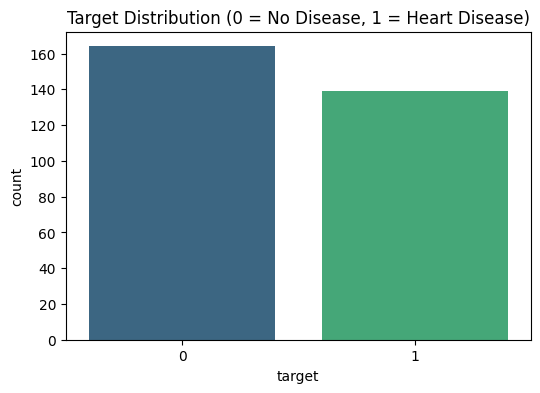

In [ ]:
# TODO: Count target classes, compute percentages, and plot the distribution

target_counts = df["target"].value_counts()
target_percentages = df["target"].value_counts(normalize=True) * 100

print("Counts:\n", target_counts)
print("\nPercentages:\n", target_percentages)

# Plot
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="target", palette="viridis")
plt.title("Target Distribution (0 = No Disease, 1 = Heart Disease)")
plt.show()

The dataset is balanced. There are roughly 54% absence (0) and 46% presence (1) cases. Because the classes are very close in size, we do not need to apply aggressive imbalance techniques (like SMOTE or heavy class weighting). Accuracy will be a reliable metric.

## Cell 6 — Missing Values and Data Quality

Check the dataset for:
- Missing / null values (remember '?' may need to be converted to NaN first)
- Duplicate rows
- Data types of each column
- Unique values per column

Identify which columns have missing values and decide how you will handle them (this decision is used later in preprocessing).

In [ ]:
# TODO: Check for missing values, duplicates, dtypes, and unique values per column

print("Missing values per column:\n", df.isnull().sum())
print("\nNumber of duplicate rows:", df.duplicated().sum())
print("\nUnique values per column:\n", df.nunique())

# Droping duplicates
df = df.drop_duplicates()

Missing values per column:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Number of duplicate rows: 0

Unique values per column:
 age          41
sex           2
cp            4
trestbps     50
chol        152
fbs           2
restecg       3
thalach      91
exang         2
oldpeak      40
slope         3
ca            4
thal          3
target        2
dtype: int64




The dataset has 4 missing values in `ca` and 2 in `thal`, with no duplicate rows. Missing values will be handled using imputation during preprocessing rather than removing observations.


## Cell 7 — Data Visualization

Create and briefly interpret:
- Target distribution plot
- At least 2 additional visualizations of your choice (e.g. age distribution, feature vs. target)
- Correlation heatmap of numerical features

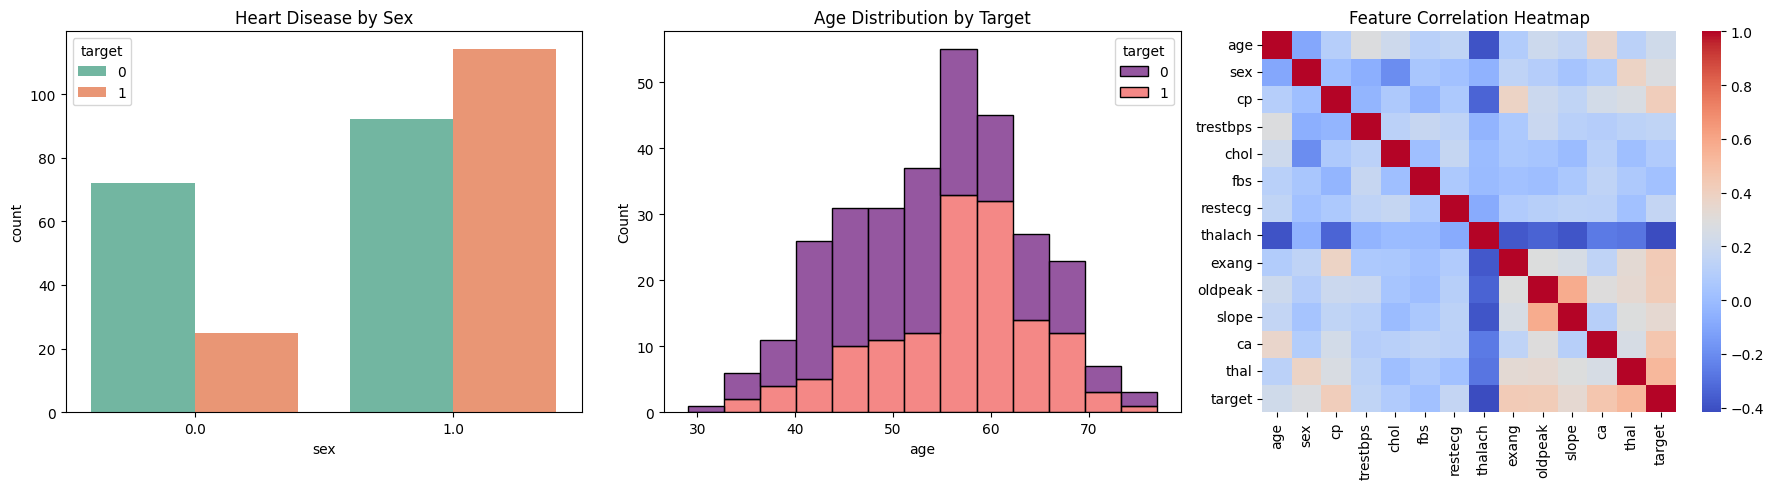

In [ ]:
# TODO: Create the required visualizations

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Target Distribution by Sex
sns.countplot(data=df, x="sex", hue="target", ax=axes[0], palette="Set2")
axes[0].set_title("Heart Disease by Sex")

# 2. Age Distribution vs Target
sns.histplot(data=df, x="age", hue="target", multiple="stack", ax=axes[1], palette="magma")
axes[1].set_title("Age Distribution by Target")

# 3. Correlation Heatmap
sns.heatmap(df.corr(), annot=False, cmap="coolwarm", ax=axes[2])
axes[2].set_title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

Interpretation of Visualizations

Heart Disease by Sex: Sex shows a noticeable difference. Females (Sex = 0) have fewer heart disease cases, while males (Sex = 1) have a higher proportion of cases.

Age Distribution by Target: Heart disease is more common among older patients, especially ages 55–65, with very few cases under 40.

Feature Correlation Heatmap: exang, oldpeak, ca, and thal are positively correlated with the target, while thalach and cp show negative correlations. These correlations indicate associations, not causation.

## Cell 8 — Preprocessing

- Separate features `X` and target `y`
- Identify numerical and categorical features
- Handle missing values (based on your Cell 6 decision)
- Encode categorical variables
- Scale numerical features where appropriate
- Split into training and testing sets

Build a preprocessing pipeline (e.g. `ColumnTransformer`) and fit it only on the training data to avoid data leakage.

In [ ]:
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define X and y
X = df.drop(columns=["target"])
y = df["target"]

# 1. Split into train/test sets FIRST to prevent data leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Setup preprocessing pipelines
numeric_features = ["age", "trestbps", "chol", "thalach", "oldpeak"]
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# 3. Fit on train, transform on train and test
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Check the new number of features after One-Hot Encoding
input_dim = X_train_processed.shape[1]
print(f"New feature input dimension: {input_dim}")

# 4. Convert to PyTorch tensors
X_train_tensor = torch.tensor(X_train_processed, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_processed, dtype=torch.float32)

# Using float32 and unsqueezing for BCEWithLogitsLoss
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

# 5. Create TensorDatasets and DataLoaders
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

New feature input dimension: 28


## Cell 9 — Design Your Own Neural Network

I designed a feed-forward neural network with two hidden layers. The first hidden
layer contains 16 neurons and the second hidden layer contains 8 neurons.
ReLU activation is used in both hidden layers. The output layer contains one
neuron and produces a raw logit for binary classification.

| Layer    | Neurons | Activation |
|----------|--------:|------------|
| Input    | 28      | None       |
| Hidden 1 | 16      | ReLU       |
| Hidden 2 | 8       | ReLU       |
| Output   | 1       | None (Logit) |


## Cell 10 — Manually Calculate Parameters

The number of trainable parameters for each layer is calculated using:

**Parameters = (Input Units × Output Units) + Output Units**

| Layer    | Input Units | Output Units | Calculation | Parameters |
|----------|------------:|-------------:|-------------|-----------:|
| Hidden 1 | 28 | 16 | (28 × 16) + 16 | 464 |
| Hidden 2 | 16 | 8 | (16 × 8) + 8 | 136 |
| Output   | 8 | 1 | (8 × 1) + 1 | 9 |
| **Total** | | | | **609** |

Therefore, the neural network has **609 trainable parameters**.


## Cell 11 — Implement Neural Network in PyTorch


In [ ]:
import torch.nn as nn

class MyModel(nn.Module):
    def __init__(self, input_dim, hidden1_dim, hidden2_dim, output_dim):
        super().__init__()

        self.model = nn.Sequential(
            # Input → Hidden 1
            nn.Linear(input_dim, hidden1_dim),
            nn.ReLU(),

            # Hidden 1 → Hidden 2
            nn.Linear(hidden1_dim, hidden2_dim),
            nn.ReLU(),

            # Hidden 2 → Output (Returns raw logits)
            nn.Linear(hidden2_dim, output_dim)
        )

    def forward(self, x):
        return self.model(x)

# Create model dynamically using the input_dim calculated in Cell 8
model = MyModel(
    input_dim=input_dim,
    hidden1_dim=16,
    hidden2_dim=8,
    output_dim=1
)

print(model)

# Verify parameters count matches our manual table
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total Trainable Parameters: {total_params}")

MyModel(
  (model): Sequential(
    (0): Linear(in_features=28, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=8, bias=True)
    (3): ReLU()
    (4): Linear(in_features=8, out_features=1, bias=True)
  )
)
Total Trainable Parameters: 609


## Cell 12 — Choose Loss Function

Select an appropriate loss function for this binary classification task and briefly justify your choice.

In [ ]:

# Using BCEWithLogitsLoss because our network outputs raw, unnormalized scores (no Sigmoid at the end).
# It combines a Sigmoid layer and the BCELoss in one single class, which is more numerically stable.
loss_function = nn.BCEWithLogitsLoss()



## Cell 13 — Choose Optimizer

Choose an optimizer and briefly justify your choice.

In [ ]:

# Adam is highly robust, adapts learning rates for individual parameters, and handles sparse gradients well.
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

## Cell 14 — Compile the Model

In [ ]:

num_epochs = 50
train_losses = []
val_losses = []

for epoch in range(num_epochs):

    # --- TRAINING ---
    model.train()
    batch_train_losses = []

    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()

        # Forward pass
        outputs = model(X_batch)

        # Loss calculation
        loss = loss_function(outputs, y_batch)

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        batch_train_losses.append(loss.item())

    train_losses.append(np.mean(batch_train_losses))

    # --- VALIDATION ---
    model.eval()
    batch_val_losses = []
    with torch.no_grad():
        for X_val, y_val in test_loader:
            outputs_val = model(X_val)
            val_loss = loss_function(outputs_val, y_val)
            batch_val_losses.append(val_loss.item())

    val_losses.append(np.mean(batch_val_losses))

    if (epoch+1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {train_losses[-1]:.4f} | Val Loss: {val_losses[-1]:.4f}")

Epoch [10/50] | Train Loss: 0.3139 | Val Loss: 0.2770
Epoch [20/50] | Train Loss: 0.2216 | Val Loss: 0.3005
Epoch [30/50] | Train Loss: 0.1388 | Val Loss: 0.3629
Epoch [40/50] | Train Loss: 0.0915 | Val Loss: 0.4828
Epoch [50/50] | Train Loss: 0.0573 | Val Loss: 0.5579


## Cell 15 — Plot Training and Validation Loss

Plot training loss vs. validation loss across epochs, then briefly comment on whether there are signs of overfitting.

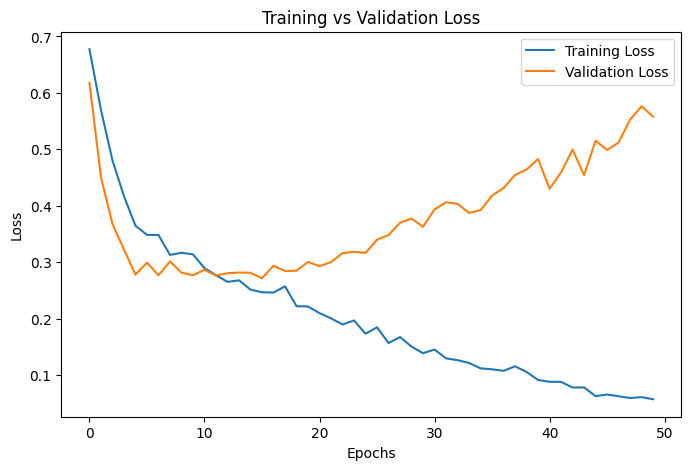

In [ ]:
# TODO: Plot training and validation loss from `history`

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label='Training Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()


Based on the plot and the loss values, there are clear signs of overfitting. The training loss decreases steadily toward zero (ending around 0.05), but the validation loss begins to increase after epoch 10 (climbing up to ~0.55 by epoch 50). This divergence indicates that the model is memorizing the training data rather than learning generalizable patterns.

## Cell 17 — Evaluate Neural Network

Make predictions on the test set and calculate accuracy, precision, recall, and F1-score.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model.eval()

y_true = []
y_prob = []

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        outputs = model(X_batch)
        # Apply sigmoid to convert logits to probabilities
        probabilities = torch.sigmoid(outputs).squeeze()

        # Handle cases where batch size is 1 (squeezing removes all 1-dims)
        if probabilities.dim() == 0:
            probabilities = probabilities.unsqueeze(0)

        y_prob.extend(probabilities.cpu().numpy())
        y_true.extend(y_batch.squeeze().cpu().numpy())

# Convert probabilities to binary predictions
threshold = 0.5
y_pred_nn = [1 if p >= threshold else 0 for p in y_prob]

# Calculate metrics
acc_nn = accuracy_score(y_true, y_pred_nn)
prec_nn = precision_score(y_true, y_pred_nn, zero_division=0)
rec_nn = recall_score(y_true, y_pred_nn, zero_division=0)
f1_nn = f1_score(y_true, y_pred_nn, zero_division=0)

print(f"Neural Network Evaluation:")
print(f"Accuracy : {acc_nn:.4f}")
print(f"Precision: {prec_nn:.4f}")
print(f"Recall   : {rec_nn:.4f}")
print(f"F1-score : {f1_nn:.4f}")

Neural Network Evaluation:
Accuracy : 0.8197
Precision: 0.7931
Recall   : 0.8214
F1-score : 0.8070


## Cell 18 — Build AdaBoost Classifier

Build a second model using `AdaBoostClassifier`:
- Create the model
- Train it
- Make predictions
- Calculate accuracy, precision, recall, and F1-score

In [ ]:

from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# TODO: Create, train, and evaluate an AdaBoostClassifier
# We use the default 50 estimators (decision stumps)
ada_model = AdaBoostClassifier(n_estimators=50, random_state=42)

# TODO: Fit on training data
ada_model.fit(X_train_processed, y_train)

# TODO: Predict on test data
y_pred_ada = ada_model.predict(X_test_processed)

# TODO: Calculate and display accuracy, precision, recall, and F1-score
acc_ada = accuracy_score(y_test, y_pred_ada)
prec_ada = precision_score(y_test, y_pred_ada, zero_division=0)
rec_ada = recall_score(y_test, y_pred_ada, zero_division=0)
f1_ada = f1_score(y_test, y_pred_ada, zero_division=0)

print("AdaBoost Evaluation:")
print(f"Accuracy : {acc_ada:.4f}")
print(f"Precision: {prec_ada:.4f}")
print(f"Recall   : {rec_ada:.4f}")
print(f"F1-score : {f1_ada:.4f}")

AdaBoost Evaluation:
Accuracy : 0.8852
Precision: 0.8182
Recall   : 0.9643
F1-score : 0.8852


## Cell 19 — Compare Both Models

| Model          | Accuracy | Precision | Recall | F1-Score |
|----------------|---------:|----------:|-------:|---------:|
| Neural Network | 0.819672 | 0.793103  | 0.821429 | 0.807018 |
| AdaBoost       | 0.885246 | 0.818182  | 0.964286 | 0.885246 |

Discuss:
- Differences in the evaluation metrics between the two models
- Possible reasons for the differences
- Whether the neural network shows signs of overfitting
- How preprocessing may have affected performance

In [ ]:

import pandas as pd

# TODO: Optionally build a small DataFrame to display the comparison table
comparison_df = pd.DataFrame({
    'Model': ['Neural Network', 'AdaBoost'],
    'Accuracy': [acc_nn, acc_ada],
    'Precision': [prec_nn, prec_ada],
    'Recall': [rec_nn, rec_ada],
    'F1-Score': [f1_nn, f1_ada]
})

# Display the formatted table
display(comparison_df)

,Model,Accuracy,Precision,Recall,F1-Score
0,Neural Network,0.819672,0.793103,0.821429,0.807018
1,AdaBoost,0.885246,0.818182,0.964286,0.885246


## Model Comparison and Analysis

### Differences in Metrics

On the test set, the Neural Network achieved an accuracy of 81.97%,
precision of 79.31%, recall of 82.14%, and F1-score of 80.70%.
AdaBoost achieved an accuracy of 88.52%, precision of 81.82%,
recall of 96.43%, and F1-score of 88.52%.

Thus, the two models produced different results across all four
evaluation metrics. In this experiment, AdaBoost obtained higher
values for accuracy, precision, recall, and F1-score.

### Possible Reasons for Differences

The dataset is relatively small, containing only 303 observations.
The Neural Network was trained on approximately 242 training
observations, which limits the amount of data available for learning.
AdaBoost combines multiple weak learners, which can work effectively
on structured tabular data. The difference in performance may also
be related to the different learning mechanisms and model settings
used by the two algorithms.

### Signs of Overfitting

The Neural Network showed signs of overfitting. The training loss
continued to decrease from 0.3139 at epoch 10 to 0.0573 at epoch 50,
while the validation loss initially decreased but then increased
from 0.2770 at epoch 10 to 0.5579 at epoch 50. This divergence
suggests that the model was fitting the training data increasingly
well while its validation performance deteriorated.

### Impact of Preprocessing

Preprocessing was particularly important for the Neural Network.
The numerical features have different scales, so standardizing them
helps gradient-based optimization operate more consistently.

Categorical features were one-hot encoded, increasing the original
13 predictor variables to 28 processed input features. Missing
values in `ca` and `thal` were handled using imputation rather than
removing observations. This allowed all 303 observations to remain
available for the analysis while ensuring that the preprocessing
was fitted only on the training data to avoid data leakage.


---

## Cell 20 — Final Interpretation

In a few sentences each, discuss:
1. Whether the dataset is balanced or imbalanced
2. The important preprocessing steps you applied
3. Your neural network architecture and design choices
4. Neural network evaluation results
5. AdaBoost evaluation results
6. Comparison between the two models
7. Possible improvements for future work

## Answer:

### Balance

The dataset is relatively balanced, with 164 patients (54.13%) in the
no-disease class and 139 patients (45.87%) in the disease class. The
difference between the two classes is relatively small, so both classes
were represented in the train and test sets using stratified splitting.
Accuracy, precision, recall, and F1-score were therefore used to evaluate
the models.

### Preprocessing

A `ColumnTransformer` was used to process numerical and categorical
features separately. Missing numerical values were imputed using the
median, while missing categorical values were imputed using the most
frequent value. Numerical features were standardized using
`StandardScaler`, and categorical features were one-hot encoded using
`OneHotEncoder`. The preprocessing increased the original 13 predictor
features to 28 processed input features. The preprocessing was fitted
only on the training data to avoid data leakage.

### Architecture

The Neural Network used a four-layer architecture:

**Input[28] → Hidden[16] → Hidden[8] → Output[1]**

ReLU activations were used in the two hidden layers. The output layer
produced a single raw logit, and `BCEWithLogitsLoss` was used for binary
classification. The network contained 609 trainable parameters.

### Neural Network Results

On the test set, the Neural Network achieved an accuracy of 81.97%,
precision of 79.31%, recall of 82.14%, and F1-score of 80.70%.

The training curves showed signs of overfitting. Training loss continued
to decrease while validation loss increased after initially decreasing.
This indicates that the network increasingly fitted the training data
while validation performance deteriorated.

### AdaBoost Results

On the same test set, AdaBoost achieved an accuracy of 88.52%, precision
of 81.82%, recall of 96.43%, and F1-score of 88.52%.

### Comparison

In this particular train/test experiment, AdaBoost produced higher
accuracy, precision, recall, and F1-score than the Neural Network.
The difference may be related to the small sample size, the tabular
nature of the dataset, and the different learning mechanisms and
hyperparameters of the two models.

### Improvements

Future experiments could use early stopping and dropout to reduce
overfitting in the Neural Network. Hyperparameter tuning could also be
used for both models. For AdaBoost, parameters such as `learning_rate`
and `n_estimators` could be tuned. K-fold cross-validation could provide
a more reliable estimate of model performance across different
train/test splits.
